# Shallow Neural Network with one hidden layer

<a name='1'></a>
# 1 - Packages


In [68]:
# Package imports
import os
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
from time import perf_counter     
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler


<a name='2'></a>
# 2 - Load the Dataset


In [69]:
# Loading the data
weather_2021 = pd.read_csv("Data/ninja_weather_2021.csv", comment="#")
weather_2022 = pd.read_csv("Data/ninja_weather_2022.csv", comment="#")
weather_2023 = pd.read_csv("Data/ninja_weather_2023.csv", comment="#")
weather_2024 = pd.read_csv("Data/ninja_weather_2024.csv", comment="#")
weather_2025 = pd.read_csv("Data/ninja_weather_2025.csv", comment="#")

pv_2021 = pd.read_csv("Data/ninja_pv_2021.csv", comment="#")
pv_2022 = pd.read_csv("Data/ninja_pv_2022.csv", comment="#")
pv_2023 = pd.read_csv("Data/ninja_pv_2023.csv", comment="#")
pv_2024 = pd.read_csv("Data/ninja_pv_2024.csv", comment="#")
pv_2025 = pd.read_csv("Data/ninja_pv_2025.csv", comment="#")

# put the years together
weather = pd.concat([weather_2021, weather_2022, weather_2023, weather_2024, weather_2025], ignore_index=True)
pv = pd.concat([pv_2021, pv_2022, pv_2023, pv_2024, pv_2025], ignore_index=True)

# merge weather and pv into one big data set (matched by timestamp)
data = pd.merge(weather, pv, on="time")

data["time"] = pd.to_datetime(data["time"])    # timestamps as datetime
data = data.set_index("time")                  # datetime index

time = data.index                              # keep the timestamps
input_data = data.values                       # .values converts a pandas dataframe to a numpy array

In [ ]:
#Categorizing the data into inputs (x) and outputs (y) as well as training set and testing set
split = int((time < "2025-01-01").sum())      # training: all hours before 2025, test: 2025
# split = int(0.8 * input_data.shape[0])      # alternative: 80/20 split

train_set_x_orig = input_data[:split, 0:8] # columns: 8 columns inputs, last one output
test_set_x_orig = input_data[split:, 0:8]
train_set_y_orig = input_data[:split, -1:]
test_set_y_orig = input_data[split:, -1:]

In [71]:
m_train = train_set_x_orig.shape[0]
m_test = test_set_x_orig.shape[0]
print ("Number of training examples: m_train = " + str(m_train))
print ("Number of testing examples: m_test = " + str(m_test))

Number of training examples: m_train = 35064
Number of testing examples: m_test = 8760


<a name='3'></a>
## 3 - Neural Network model

**Mathematically**:

For one example $x^{(i)}$:
$$
z^{[1] (i)} =  W^{[1]} x^{(i)} + b^{[1]}\tag{1}
$$ 
$$
a^{[1] (i)} = \tanh(z^{[1] (i)})\tag{2}
$$
$$
z^{[2] (i)} = W^{[2]} a^{[1] (i)} + b^{[2]}\tag{3}
$$
$$
\hat{y}^{(i)} = a^{[2] (i)} = \sigma(z^{ [2] (i)})\tag{4}
$$

Given the predictions on all the examples, you can also compute the cost $J$ as follows: 
$$J = - \frac{1}{m} \sum\limits_{i = 0}^{m} \large\left(\small y^{(i)}\log\left(a^{[2] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[2] (i)}\right)  \large  \right) \small \tag{5}$$

<a name='3-1'></a>
### 3.1 - Defining the neural network structure ####



In [72]:
def layer_sizes(X, Y):

    n_x = X.shape[0]
    n_y = Y.shape[0]

    return (n_x, n_y)

<a name='3-2'></a>
### 3.2 - Initialize the model's parameters ####

<a name='ex-3'></a>
### Exercise 3 -  initialize_parameters

Create a function as `initialize_parameters()`, which receives n_x, n_h, and n_y as inputs. As output, create a python dictionary containing parameters W1, b1, w2, and b2 with their initial values. 

Hint:
- Make sure your parameters' sizes are right. Refer to the neural network figure above if needed.

In [73]:
# initialize_parameters
def initialize_parameters(n_x,n_h,n_y):
   
    W1 = np.random.randn(n_h, n_x) * 0.01
    b1 = np.zeros((n_h,1))
    W2 = np.random.randn(n_y, n_h) * 0.01
    b2 = np.zeros((n_y,1))
    
    parameters = {
        "W1" : W1,
        "b1" : b1,
        "W2" : W2,
        "b2" : b2
        }
   
    return parameters

In [74]:
def sigmoid(z):
    s=1/(1+np.exp(-z))
    return s

<a name='3-3'></a>
### 3.3 - The Loop 

<a name='ex-4'></a>
### Exercise 4 - forward_propagation

Create a function as `forward_propagation()` which receives X and parameters as inputs. Then use the following equations:

$$
Z^{[1]} =  W^{[1]} X + b^{[1]}\tag{6}
$$ 
$$
A^{[1]} = \tanh(Z^{[1]})\tag{7}
$$
$$
Z^{[2]} = W^{[2]} A^{[1]} + b^{[2]}\tag{8}
$$
$$
\hat{Y} = A^{[2]} = \sigma(Z^{[2]})\tag{9}
$$

As output, make a dictionary named "cache" and put Z1, A1, Z2, A2 in it. Finally return A2 ansd cache.

In [75]:
def forward_propagation(X, parameters):
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    b1 = parameters["b1"]
    b2 = parameters["b2"]

    Z1 = W1 @ X + b1                 # matrix multiplicaation either with @ instead of * or with np.dot() or np.matmul()
    A1 = np.tanh((Z1))
    Z2 = W2 @ A1 + b2
    A2 = sigmoid((Z2))

    cache = {
        "Z1" : Z1,
        "A1" : A1,
        "Z2" : Z2,
        "A2" : A2
    }

    return A2, cache

<a name='3-4'></a>
### 3.4 - Compute the Cost

Now that you've computed $A^{[2]}$ (in the Python variable "`A2`"), which contains $a^{[2](i)}$ for all examples, you can compute the cost function as follows:

$$J = - \frac{1}{m} \sum\limits_{i = 1}^{m} \large{(} \small y^{(i)}\log\left(a^{[2] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[2] (i)}\right) \large{)} \small\tag{10}$$

<a name='ex-5'></a>


In [76]:
def compute_cost(A2, Y):
    m = Y.shape[1]
    logprobs = np.multiply(np.log(A2), Y) + np.multiply(np.log(1 - A2), (1 - Y))
    cost = -1/m * np.sum(logprobs)
    
    cost = float(np.squeeze(cost))  
    return cost

<a name='3-5'></a>
### 3.5 - Backpropagation

<!-- $\frac{\partial \mathcal{J} }{ \partial z_{2}^{(i)} } = \frac{1}{m} (a^{[2](i)} - y^{(i)})$

$\frac{\partial \mathcal{J} }{ \partial W_2 } = \frac{\partial \mathcal{J} }{ \partial z_{2}^{(i)} } a^{[1] (i) T} $

$\frac{\partial \mathcal{J} }{ \partial b_2 } = \sum_i{\frac{\partial \mathcal{J} }{ \partial z_{2}^{(i)}}}$

$\frac{\partial \mathcal{J} }{ \partial z_{1}^{(i)} } =  W_2^T \frac{\partial \mathcal{J} }{ \partial z_{2}^{(i)} } * ( 1 - a^{[1] (i) 2}) $

$\frac{\partial \mathcal{J} }{ \partial W_1 } = \frac{\partial \mathcal{J} }{ \partial z_{1}^{(i)} }  X^T $

$\frac{\partial \mathcal{J} _i }{ \partial b_1 } = \sum_i{\frac{\partial \mathcal{J} }{ \partial z_{1}^{(i)}}}$

- Note that $*$ denotes elementwise multiplication.
- The notation you will use is common in deep learning coding:
    - dW1 = $\frac{\partial \mathcal{J} }{ \partial W_1 }$
    - db1 = $\frac{\partial \mathcal{J} }{ \partial b_1 }$
    - dW2 = $\frac{\partial \mathcal{J} }{ \partial W_2 }$
    - db2 = $\frac{\partial \mathcal{J} }{ \partial b_2 }$
    
!-->



In [77]:
# GRADED FUNCTION: backward_propagation
def backward_propagation(parameters, cache, X, Y):
    m = X.shape[1]
    A1 = cache["A1"]
    A2 = cache["A2"]
    W1 = parameters["W1"]
    W2 = parameters["W2"]

    dZ2 = A2 - Y
    dW2 = 1/m * dZ2 @ A1.T
    db2 = 1 /m * np.sum(dZ2, axis=1, keepdims=True)
    dZ1 = W2.T @ dZ2 * (1 - np.power(A1, 2))     
    dW1 = 1/m * dZ1 @ X.T
    db1 = 1/m * np.sum(dZ1, axis = 1, keepdims = True)
   
    grads = {"dW1": dW1,
             "db1": db1,
             "dW2": dW2,
             "db2": db2}

    return grads

### Update Parameters

In [78]:
def update_parameters(parameters, grads, learning_rate=1.2):
    W1 = copy.deepcopy(parameters["W1"])
    b1 = parameters["b1"]
    W2 = copy.deepcopy(parameters["W2"])
    b2 = parameters["b2"]

    dW1 = grads["dW1"]
    db1 = grads["db1"]
    dW2 = grads["dW2"]
    db2 = grads["db2"]
    
    W1 = W1 - learning_rate*dW1
    b1 = b1 - learning_rate*db1
    W2 = W2 - learning_rate*dW2
    b2 = b2 - learning_rate*db2

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

<a name='3-7'></a>
### 3.7 - Integration

Integrate your functions in `nn_model()` 

Build your neural network model in `nn_model()`.

**Instructions**: The neural network model has to use the previous functions in the right order.

In [79]:
def nn_model(X, Y, n_h, num_iterations = 1000, learning_rate=0.85, print_cost=True):

    np.random.seed(3)
    n_x, n_y = layer_sizes(X, Y)

    parameters = initialize_parameters(n_x, n_h, n_y)

    costs = []

    # Loop (gradient descent)

    for i in range(0, num_iterations):
        A2, cache = forward_propagation(X, parameters)
        cost = compute_cost(A2, Y)
        grads = backward_propagation(parameters, cache, X, Y)
        parameters = update_parameters(parameters, grads, learning_rate)

        # Print the cost every 100 iterations
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print ("Cost after iteration %i: %f" %(i, cost))
    return parameters, costs

<a name='4'></a>
## 4 - Test the Model

<a name='4-1'></a>
### 4.1 - Predict

In [80]:
def predict(parameters, X):
    A2, cache = forward_propagation(X, parameters)
    predictions = A2

    return predictions

In [81]:
# new, combines nn_model and predict
def model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, n_h, num_iterations=1000, learning_rate=0.85, print_cost=False):

    # tic-toc: time needed for the optimization (training)
    tic = perf_counter()
    parameters, costs = nn_model(train_set_x_normalized, train_set_y_normalized, n_h, num_iterations, learning_rate, print_cost)
    toc = perf_counter()

    Y_prediction_test = predict(parameters, test_set_x_normalized)
    Y_prediction_train = predict(parameters, train_set_x_normalized)

    # Print train/test Errors
    if print_cost:
        #print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100))
        #print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - test_set_y_normalized)) * 100))
        #print("training time: {:.2f} s".format(toc - tic))
        print (evaluate(test_set_y_normalized, Y_prediction_test))


    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test,
         "Y_prediction_train": Y_prediction_train,
         "parameters": parameters,
         "n_h": n_h,
         "learning_rate": learning_rate,
         "num_iterations": num_iterations,
         "train_time": toc - tic}
    return d

### Evaluation based upon L9

All errors are computed in kW (after reversing the normalization) and the same function is used for the cross-validation (train and validation folds) and for the final model (train and test set), so that all numbers can be compared directly.

| Metric | Formula | Meaning |
|---|---|---|
| MAE | $\frac{1}{m}\sum \lvert \hat{y}-y \rvert$ | mean absolute error in kW |
| MSE | $\frac{1}{m}\sum (\hat{y}-y)^2$ | mean squared error in kW² |
| RMSE | $\sqrt{MSE}$ | penalizes large errors more than MAE, in kW |
| R² | $1 - \frac{\sum (\hat{y}-y)^2}{\sum (y-\bar{y})^2}$ | share of the variance that the model explains |

MAPE is not used because the PV output is 0 during the night (division by zero).

In [82]:
capacity = 1000    # installed capacity in kW (Renewables.ninja setting), used for the normalized errors

def evaluate(y_true, y_pred):
    error = y_pred - y_true
    mae = np.mean(np.abs(error))
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)
    r2 = 1 - np.sum(error ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return {"MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2": r2}



metrics = list(evaluate(np.array([0.0, 1.0]), np.array([0.0, 1.0])).keys())    # names of all metrics

In [83]:
# Shared results file (same function as in 01_Logistic_Regression)
model_name = "Shallow NN"
results_file = "results/model_comparison.xlsx"

def save_results(tables, model_name, file=results_file):
    # tables: {sheet name: DataFrame}. Old rows of the same model are replaced, rows of other models are kept
    os.makedirs(os.path.dirname(file), exist_ok=True)
    sheets = pd.read_excel(file, sheet_name=None) if os.path.exists(file) else {}

    for sheet, table in tables.items():
        old = sheets.get(sheet, pd.DataFrame())
        if "model" in old.columns:
            old = old[old["model"] != model_name]
        sheets[sheet] = pd.concat([old, table], ignore_index=True)

    with pd.ExcelWriter(file) as writer:
        for sheet, table in sheets.items():
            table.to_excel(writer, sheet_name=sheet, index=False)

In [84]:
# cross-validation: rolling window with a gap (only on the training set)
n_splits = 5
gap = 24                 # 24 h gap between training and validation
train_share = 0.5        # share of the training set that one fold uses for training TO BE JUSTIFIED LATER

n_train = len(train_set_x_orig)
val_size = int((n_train - gap) * (1 - train_share) / n_splits)   # validation hours per fold
train_window = n_train - n_splits * val_size - gap               # training hours per fold

tscv = TimeSeriesSplit(n_splits=n_splits, max_train_size=train_window, gap=gap, test_size=val_size)

def cross_validate(n_h, num_iterations, learning_rate):

    train_scores = []
    val_scores = []
    train_times = []

    for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
        x_train = train_set_x_orig[train_idx]
        x_val = train_set_x_orig[val_idx]
        y_train = train_set_y_orig[train_idx]
        y_val = train_set_y_orig[val_idx]

        # normalization: fit only on the training fold, then apply to the validation fold
        scaler_x = MinMaxScaler(feature_range=(0,1))
        scaler_y = MinMaxScaler(feature_range=(0,1))
        x_train_normalized = scaler_x.fit_transform(x_train)
        x_val_normalized = scaler_x.transform(x_val)
        y_train_normalized = scaler_y.fit_transform(y_train)
        y_val_normalized = scaler_y.transform(y_val)

        # transpose: features in the rows, samples in the columns
        x_train_normalized = x_train_normalized.T
        x_val_normalized = x_val_normalized.T
        y_train_normalized = y_train_normalized.T
        y_val_normalized = y_val_normalized.T

        # train on the training fold, predict the validation fold
        fold_model = model(x_train_normalized, y_train_normalized, x_val_normalized, y_val_normalized, n_h, num_iterations, learning_rate)

        # reverse normalization (back to kW) and evaluation on both the training and the validation fold
        y_train_pred_kw = scaler_y.inverse_transform(fold_model["Y_prediction_train"].T)
        y_val_pred_kw = scaler_y.inverse_transform(fold_model["Y_prediction_test"].T)
        train_scores.append(evaluate(y_train, y_train_pred_kw))
        val_scores.append(evaluate(y_val, y_val_pred_kw))
        train_times.append(fold_model["train_time"])

    return pd.DataFrame(train_scores), pd.DataFrame(val_scores), train_times


# hyperparameter selection with the cross-validation
n_h_list = [2, 4, 8]          # hidden units
learning_rates = [0.1, 0.85, 2.0]
iterations_list = [1000, 3000, 5000]

cv_results = []
best_rmse = np.inf
tic_cv = perf_counter()

for n_h in n_h_list:
    for learning_rate in learning_rates:
        for num_iterations in iterations_list:
            train_scores, val_scores, train_times = cross_validate(n_h, num_iterations, learning_rate)

            # one row per setting: mean over the folds (and std of the validation errors)
            row = {"n_h": n_h, "learning_rate": learning_rate, "num_iterations": num_iterations}
            row.update(train_scores.mean().add_prefix("train_").to_dict())
            row.update(val_scores.mean().add_prefix("val_").to_dict())
            row.update(val_scores.std(ddof=0).add_prefix("val_std_").to_dict())
            row["train_time_per_fold_s"] = np.mean(train_times)
            row["time_per_iteration_ms"] = np.mean(train_times) / num_iterations * 1000
            cv_results.append(row)

            print("hidden units:", n_h, "| learning rate:", learning_rate, "| iterations:", num_iterations,
                  "| mean val MAE = %.2f, RMSE = %.2f, R2 = %.4f" % (row["val_MAE"], row["val_RMSE"], row["val_R2"]),
                  "| training time per fold = %.2f s" % row["train_time_per_fold_s"])

            if row["val_RMSE"] < best_rmse:         # the mean validation RMSE decides
                best_rmse = row["val_RMSE"]
                best_n_h = n_h
                best_learning_rate = learning_rate
                best_num_iterations = num_iterations
                best = row
                best_val_scores = val_scores

toc_cv = perf_counter()
cv_results = pd.DataFrame(cv_results)

print("best setting: hidden units =", best_n_h, ", learning rate =", best_learning_rate, ", iterations =", best_num_iterations, ", mean RMSE =", best_rmse)
print("total time of the grid search: %.1f s" % (toc_cv - tic_cv))

# periods and validation errors per fold for the best setting
for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    print("fold", fold + 1, "| training:", time[train_idx[0]], "to", time[train_idx[-1]], "| validation:", time[val_idx[0]], "to", time[val_idx[-1]])

best_val_scores.index = ["fold %d" % (k + 1) for k in range(n_splits)]
print("validation errors per fold:")
print(best_val_scores)

cv_results

hidden units: 2 | learning rate: 0.1 | iterations: 1000 | mean val MAE = 38.92, RMSE = 62.87, R2 = 0.8452 | training time per fold = 8.33 s
hidden units: 2 | learning rate: 0.1 | iterations: 3000 | mean val MAE = 28.83, RMSE = 50.91, R2 = 0.9063 | training time per fold = 5.43 s
hidden units: 2 | learning rate: 0.1 | iterations: 5000 | mean val MAE = 25.19, RMSE = 46.31, R2 = 0.9218 | training time per fold = 8.69 s
hidden units: 2 | learning rate: 0.85 | iterations: 1000 | mean val MAE = 21.52, RMSE = 41.23, R2 = 0.9356 | training time per fold = 1.65 s
hidden units: 2 | learning rate: 0.85 | iterations: 3000 | mean val MAE = 19.54, RMSE = 37.88, R2 = 0.9477 | training time per fold = 17.57 s
hidden units: 2 | learning rate: 0.85 | iterations: 5000 | mean val MAE = 19.40, RMSE = 37.72, R2 = 0.9485 | training time per fold = 18.26 s
hidden units: 2 | learning rate: 2.0 | iterations: 1000 | mean val MAE = 20.75, RMSE = 39.28, R2 = 0.9476 | training time per fold = 4.57 s
hidden units: 2

,n_h,learning_rate,num_iterations,train_MAE,train_MSE,train_RMSE,train_R2,val_MAE,val_MSE,val_RMSE,val_R2,val_std_MAE,val_std_MSE,val_std_RMSE,val_std_R2,train_time_per_fold_s,time_per_iteration_ms
0,2,0.10,1000,39.653788,4194.186467,64.751252,0.893019,38.916986,3994.497490,62.869740,0.845164,7.711368,780.758455,6.472503,0.095706,8.326622,8.326622
1,2,0.10,3000,28.917944,2637.016669,51.348857,0.932712,28.828593,2652.008211,50.909134,0.906254,6.453192,707.697651,7.763265,0.040515,5.430884,1.810295
2,2,0.10,5000,24.916897,2104.831557,45.874844,0.946287,25.188151,2195.019606,46.307030,0.921846,5.764251,592.030376,7.118891,0.034689,8.687993,1.737599
3,2,0.85,1000,20.880505,1594.425509,39.923306,0.959313,21.522801,1736.678969,41.228563,0.935622,4.584109,471.967018,6.073268,0.033101,1.650111,1.650111
4,2,0.85,3000,18.585530,1338.919257,36.584440,0.965838,19.539355,1472.079284,37.877520,0.947737,4.983023,423.654432,6.113325,0.023204,17.572152,5.857384
5,2,0.85,5000,18.398155,1325.363572,36.399153,0.966184,19.400228,1462.404769,37.723031,0.948466,5.111180,432.060994,6.275164,0.022298,18.260373,3.652075
6,2,2.00,1000,20.181745,1557.122878,39.455955,0.960272,20.752137,1636.991696,39.281957,0.947581,7.846480,767.319119,9.691208,0.017979,4.566921,4.566921
7,2,2.00,3000,18.895283,1401.203162,37.428413,0.964248,19.628678,1485.138901,37.682471,0.951328,6.795728,586.103591,8.072811,0.016545,12.795442,4.265147
8,2,2.00,5000,18.691026,1383.958998,37.196952,0.964688,19.490918,1474.183082,37.514571,0.952140,6.887891,586.678876,8.175574,0.015261,37.520875,7.504175
9,4,0.10,1000,38.017919,3991.163363,63.165722,0.898195,37.250601,3799.672403,61.329484,0.852097,7.248079,728.548456,6.194094,0.091934,2.477296,2.477296


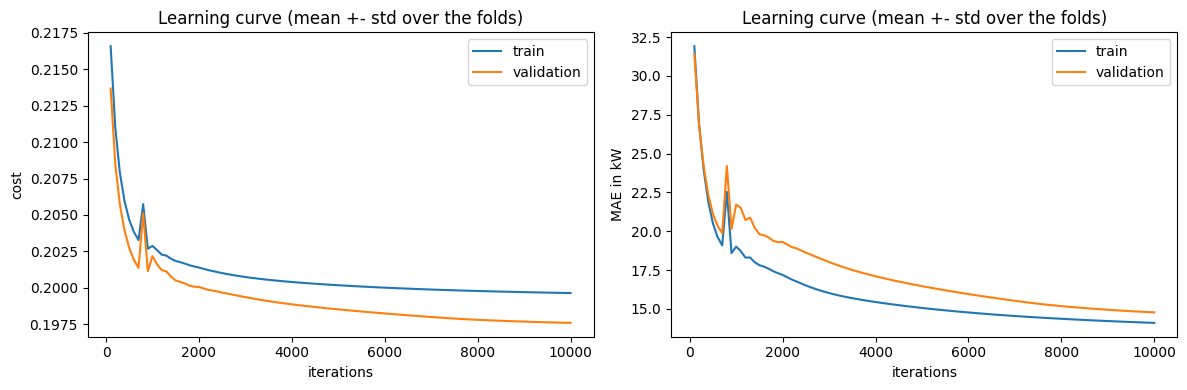

In [85]:
# learning curves: train vs validation (mean over the CV folds)
total_iterations = 10000   # long enough to see if the validation error starts to rise
step = 100                 # evaluate every 100 iterations
n_points = total_iterations // step

train_cost = np.zeros((n_splits, n_points))
val_cost = np.zeros((n_splits, n_points))
train_mae = np.zeros((n_splits, n_points))
val_mae = np.zeros((n_splits, n_points))

for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    x_train = train_set_x_orig[train_idx]
    x_val = train_set_x_orig[val_idx]
    y_train = train_set_y_orig[train_idx]
    y_val = train_set_y_orig[val_idx]

    # same normalization as in the cross-validation
    scaler_x = MinMaxScaler(feature_range=(0,1))
    scaler_y = MinMaxScaler(feature_range=(0,1))
    x_train_normalized = scaler_x.fit_transform(x_train).T
    x_val_normalized = scaler_x.transform(x_val).T
    y_train_normalized = scaler_y.fit_transform(y_train).T
    y_val_normalized = scaler_y.transform(y_val).T

    y_range = np.max(y_train) - np.min(y_train)    # to convert the normalized error back to kW

    # same initialization as in nn_model
    np.random.seed(3)
    n_x, n_y = layer_sizes(x_train_normalized, y_train_normalized)
    parameters = initialize_parameters(n_x, best_n_h, n_y)

    for k in range(n_points):
        # continue the training for another 100 iterations (same steps as in nn_model)
        for i in range(step):
            A2, cache = forward_propagation(x_train_normalized, parameters)
            grads = backward_propagation(parameters, cache, x_train_normalized, y_train_normalized)
            parameters = update_parameters(parameters, grads, best_learning_rate)

        Y_prediction_train = predict(parameters, x_train_normalized)
        Y_prediction_val = predict(parameters, x_val_normalized)

        train_cost[fold, k] = compute_cost(Y_prediction_train, y_train_normalized)
        val_cost[fold, k] = compute_cost(Y_prediction_val, y_val_normalized)

        train_mae[fold, k] = np.mean(np.abs(Y_prediction_train - y_train_normalized)) * y_range
        val_mae[fold, k] = np.mean(np.abs(Y_prediction_val - y_val_normalized)) * y_range

iterations = np.arange(step, total_iterations + 1, step)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for i, (train_curve, val_curve, label) in enumerate([(train_cost, val_cost, 'cost'), (train_mae, val_mae, 'MAE in kW')]):
    ax[i].plot(iterations, train_curve.mean(axis=0), label='train')
    ax[i].plot(iterations, val_curve.mean(axis=0), label='validation')
    ax[i].set_xlabel('iterations')
    ax[i].set_ylabel(label)
    ax[i].set_title('Learning curve (mean +- std over the folds)')
    ax[i].legend()

plt.tight_layout()
plt.show()

In [86]:
# final model: whole training set, evaluation on the test set
scaler_x = MinMaxScaler(feature_range=(0,1))
scaler_y = MinMaxScaler(feature_range=(0,1))
train_set_x_normalized = scaler_x.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler_x.transform(test_set_x_orig)
train_set_y_normalized = scaler_y.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler_y.transform(test_set_y_orig)

#Transpose the data to put all features in the rows and all samples in the columns
train_set_x_normalized = train_set_x_normalized.T     # .T Transpose a numpy array
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T

shallow_nn_model = model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, best_n_h, best_num_iterations, best_learning_rate, print_cost=True)

#Reverse normalization
Y_prediction_train_real_scale = scaler_y.inverse_transform(shallow_nn_model["Y_prediction_train"].T)
Y_prediction_test_real_scale = scaler_y.inverse_transform(shallow_nn_model["Y_prediction_test"].T)

# tic-toc: time needed to predict the whole test set
tic = perf_counter()
predict(shallow_nn_model["parameters"], test_set_x_normalized)
toc = perf_counter()
predict_time = toc - tic

train_scores = evaluate(train_set_y_orig, Y_prediction_train_real_scale)
test_scores = evaluate(test_set_y_orig, Y_prediction_test_real_scale)

# CV and test side by side (same metrics, all in kW)
comparison = pd.DataFrame({"CV train (mean)": [best["train_" + m] for m in metrics],
                           "CV validation (mean)": [best["val_" + m] for m in metrics],
                           "CV validation (std)": [best["val_std_" + m] for m in metrics],
                           "final model train": [train_scores[m] for m in metrics],
                           "test": [test_scores[m] for m in metrics]},
                          index=metrics)

# computation times (tic-toc)
times = pd.Series({"training time final model (s)": shallow_nn_model["train_time"],
                   "time per iteration (ms)": shallow_nn_model["train_time"] / best_num_iterations * 1000,
                   "prediction time test set (s)": predict_time,
                   "mean training time per CV fold, best setting (s)": best["train_time_per_fold_s"],
                   "total grid search time (s)": toc_cv - tic_cv})
print(times.to_string())

comparison

Cost after iteration 0: 0.693122
Cost after iteration 100: 0.216745
Cost after iteration 200: 0.211205
Cost after iteration 300: 0.208078
Cost after iteration 400: 0.206105
Cost after iteration 500: 0.204819
Cost after iteration 600: 0.203977
Cost after iteration 700: 0.203420
Cost after iteration 800: 0.203068
Cost after iteration 900: 0.202808
Cost after iteration 1000: 0.204358
Cost after iteration 1100: 0.202526
Cost after iteration 1200: 0.202680
Cost after iteration 1300: 0.202296
Cost after iteration 1400: 0.202156
Cost after iteration 1500: 0.202076
Cost after iteration 1600: 0.201947
Cost after iteration 1700: 0.201835
Cost after iteration 1800: 0.201753
Cost after iteration 1900: 0.201677
Cost after iteration 2000: 0.201590
Cost after iteration 2100: 0.201503
Cost after iteration 2200: 0.201427
Cost after iteration 2300: 0.201354
Cost after iteration 2400: 0.201279
Cost after iteration 2500: 0.201208
Cost after iteration 2600: 0.201143
Cost after iteration 2700: 0.201080
Cost

,CV train (mean),CV validation (mean),CV validation (std),final model train,test
MAE,15.067565,16.470422,5.247593,14.933571,15.189400
MSE,1070.330806,1268.159988,545.866182,1068.911725,1121.816178
RMSE,32.712364,34.390923,9.242532,32.694215,33.493524
R2,0.972690,0.960726,0.016249,0.972235,0.970615


<a name='5'></a>
##  5 - Results Analysis

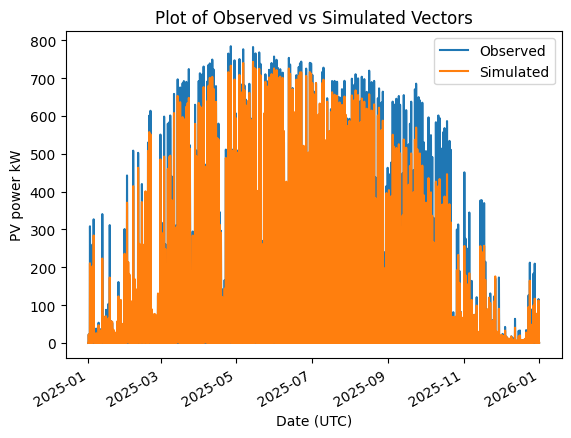

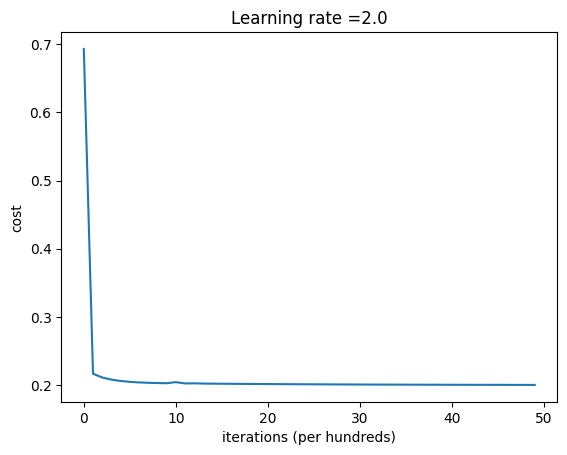

In [87]:
# Results analysis
x = time[split:]                               # datetime index of the test period
y1 = test_set_y_orig
y2 = Y_prediction_test_real_scale

plt.plot(x, y1, label='Observed')
plt.plot(x, y2, label='Simulated')
plt.title('Plot of Observed vs Simulated Vectors')
plt.xlabel('Date (UTC)')
plt.ylabel('PV power kW')
plt.ylim()
plt.legend()
plt.gcf().autofmt_xdate()                    # tilt the date labels
plt.show()

# Plot learning curve (with costs)
costs = np.squeeze(shallow_nn_model['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(shallow_nn_model["learning_rate"]))
plt.show()



## 6 - Feature Importance

Three ways to see which inputs matter for the PV output:

1. **Correlation** (Pearson, on the training set): linear relation between each input and the output, independent of the model. Fast, but it ignores interactions and non-linear effects.
2. **Sensitivity** (by hand from the equations): the derivative of the prediction with respect to each input, with the chain rule through the network:
$$\frac{\partial \hat{y}}{\partial x} = W^{[1]T} \left[ \left( W^{[2]T} \sigma'(z^{[2]}) \right) * \left(1 - a^{[1]2}\right) \right], \qquad \sigma'(z^{[2]}) = a^{[2]}(1 - a^{[2]})$$
It is computed for every hour of the test set and multiplied by the range of the output scaler, so it is in kW per unit of normalized input (all inputs are scaled to [0, 1], so the features are comparable). The mean of $|\partial \hat{y} / \partial x_j|$ gives the strength, the mean of $\partial \hat{y} / \partial x_j$ the direction. For the logistic regression this reduces to the weights $w_j$ (times $\sigma'$).

3. **Permutation importance** (on the test set): one feature is randomly shuffled, which destroys its information, and the increase of the test RMSE is measured. Same method as in the logistic regression notebook, so the models can be compared directly.

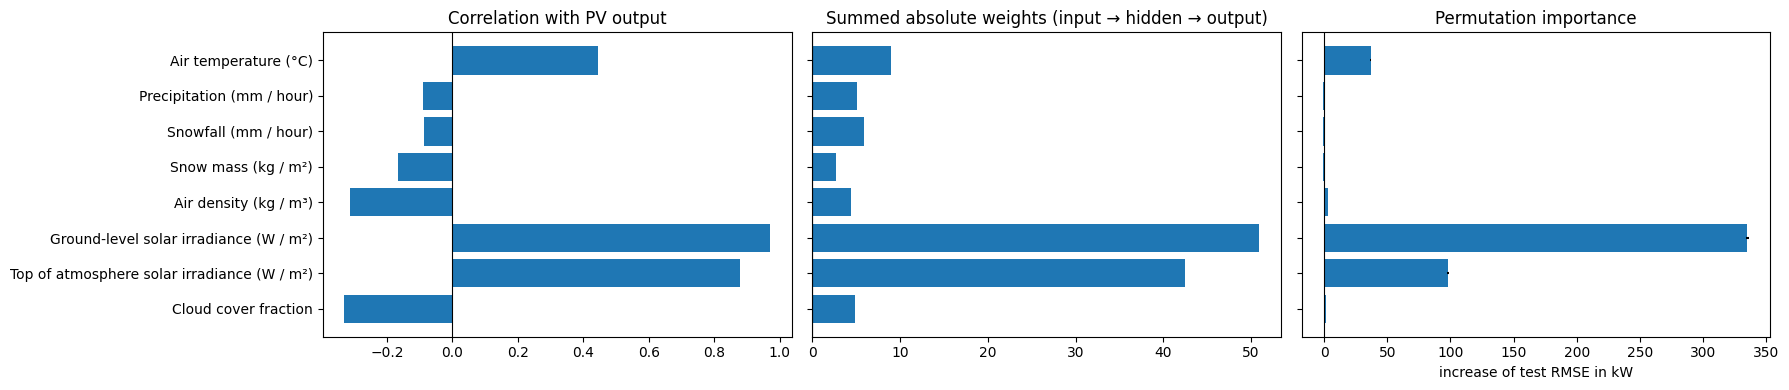

,model,feature,correlation_with_output,abs_weight,permutation_RMSE_increase_kW,permutation_RMSE_increase_std
5,Shallow NN,Ground-level solar irradiance (W / m²),0.970443,50.861535,334.875355,1.383540
6,Shallow NN,Top of atmosphere solar irradiance (W / m²),0.876634,42.490970,98.102773,0.580901
0,Shallow NN,Air temperature (°C),0.445312,9.019594,36.815325,0.466018
4,Shallow NN,Air density (kg / m³),-0.312710,4.381846,3.368374,0.135175
7,Shallow NN,Cloud cover fraction,-0.330247,4.831728,1.421144,0.163845
3,Shallow NN,Snow mass (kg / m²),-0.167275,2.719013,-0.759898,0.037490
2,Shallow NN,Snowfall (mm / hour),-0.085098,5.850502,-0.842476,0.012560
1,Shallow NN,Precipitation (mm / hour),-0.089257,5.128902,-0.859732,0.011362


In [88]:
feature_names = data.columns[0:8]
W1 = parameters["W1"]
W2 = parameters["W2"]

# readable feature names (used in the plot and in the results table)
label_map = {"t2m": "Air temperature (°C)",
             "prectotland": "Precipitation (mm / hour)",
             "precsnoland": "Snowfall (mm / hour)",
             "snomas": "Snow mass (kg / m²)",
             "rhoa": "Air density (kg / m³)",
             "swgdn": "Ground-level solar irradiance (W / m²)",
             "swtdn": "Top of atmosphere solar irradiance (W / m²)",
             "cldtot": "Cloud cover fraction"}
plot_labels = [label_map[f] for f in feature_names]

# 1. correlation of every input with the output (training set only)
correlation = data.iloc[:split].corr()[data.columns[-1]][feature_names]

# 2. weights of the model: a shallow NN has no single weight per input, so the absolute
#    paths input -> hidden unit -> output are summed up (inputs are normalized, so the values are comparable)
weights = (np.abs(W2) @ np.abs(W1)).flatten()

# 3. permutation importance: shuffle one feature of the test set and measure the increase of the RMSE in kW
n_repeats = 5
rng = np.random.default_rng(0)
base_rmse = test_scores["RMSE"]
perm_importance = np.zeros((len(feature_names), n_repeats))

for j in range(len(feature_names)):
    for r in range(n_repeats):
        x_shuffled = test_set_x_normalized.copy()
        x_shuffled[j, :] = rng.permutation(x_shuffled[j, :])
        y_shuffled_kw = scaler_y.inverse_transform(predict(parameters, x_shuffled).T)
        perm_importance[j, r] = evaluate(test_set_y_orig, y_shuffled_kw)["RMSE"] - base_rmse

feature_importance = pd.DataFrame({"model": model_name,
                                   "feature": plot_labels,
                                   "correlation_with_output": correlation.values,
                                   "abs_weight": weights,
                                   "permutation_RMSE_increase_kW": perm_importance.mean(axis=1),
                                   "permutation_RMSE_increase_std": perm_importance.std(axis=1)})

fig, ax = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

ax[0].barh(plot_labels, correlation.values)
ax[0].set_title('Correlation with PV output')
ax[1].barh(plot_labels, weights)
ax[1].set_title('Summed absolute weights (input → hidden → output)')
ax[2].barh(plot_labels, perm_importance.mean(axis=1), xerr=perm_importance.std(axis=1))
ax[2].set_title('Permutation importance')
ax[2].set_xlabel('increase of test RMSE in kW')

ax[0].invert_yaxis()    # order of the features

for a in ax:
    a.axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

feature_importance.sort_values("permutation_RMSE_increase_kW", ascending=False)

## 7 - Save the Results

Writes the CV table, the test results and the feature importance to `results/model_comparison.xlsx`, the same file as in the other notebooks. Only the rows of this model (column `model`) are replaced, so all models end up in the same tables and can be compared directly.

In [89]:
# cv_results is built in the grid search as a list of rows (dicts): convert it to a table
if isinstance(cv_results, list):
    cv_results = pd.DataFrame(cv_results)

# model column, so that save_results only replaces the rows of this model
if "model" not in cv_results.columns:
    cv_results.insert(0, "model", model_name)
if "model" not in feature_importance.columns:
    feature_importance.insert(0, "model", model_name)

# one row for the results file (same columns as in the other notebooks)
test_results = {"model": model_name, "n_h": best_n_h, "learning_rate": best_learning_rate, "num_iterations": best_num_iterations}
test_results.update({"cv_val_" + m: best["val_" + m] for m in metrics})
test_results.update({"train_" + m: train_scores[m] for m in metrics})
test_results.update({"test_" + m: test_scores[m] for m in metrics})
test_results.update({"train_time_s": shallow_nn_model["train_time"],
                     "predict_time_test_s": predict_time,
                     "grid_search_time_s": toc_cv - tic_cv})
test_results = pd.DataFrame([test_results])

# train and test periods (the notebooks do not all use the same split) and training time per iteration
test_results["train_period"] = "%s to %s" % (time[0], time[split - 1])
test_results["test_period"] = "%s to %s" % (time[split], time[-1])
test_results["time_per_iteration_ms"] = test_results["train_time_s"] / test_results["num_iterations"] * 1000

save_results({"cv": cv_results,
              "test": test_results,
              "feature_importance": feature_importance}, model_name)

print("results saved to", results_file)

results saved to results/model_comparison.xlsx
